<a href="https://colab.research.google.com/github/pwngnick1/pwngnick1.github.io/blob/main/Activity_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install lifelines

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from lifelines import KaplanMeierFitter

Path("data").mkdir(exist_ok=True)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [5]:
uploaded = files.upload()

for filename, contents in uploaded.items():
    (Path("data") / filename).write_bytes(contents)

mutations = pd.read_csv(
    "data/BRCA_mc3_gene_level.txt",
    sep="\t",
    index_col=0
)

# Download the separate survival dataset directly
survival = pd.read_csv(
    "https://tcga.xenahubs.net/download/survival/BRCA_survival.txt",
    sep="\t"
)

survival.to_csv(
    "data/survival_BRCA_survival.txt",
    sep="\t",
    index=False
)

print("Mutation table shape:", mutations.shape)
print("Survival table shape:", survival.shape)
display(survival.head())

Saving BRCA_mc3_gene_level.txt to BRCA_mc3_gene_level.txt
Mutation table shape: (40543, 791)
Survival table shape: (1236, 11)


,sample,_PATIENT,OS,OS.time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction
0,TCGA-3C-AAAU-01,TCGA-3C-AAAU,0,4047.0,0.0,4047.0,1.0,1808.0,1,1808.0,NaN
1,TCGA-3C-AALI-01,TCGA-3C-AALI,0,4005.0,0.0,4005.0,0.0,4005.0,0,4005.0,NaN
2,TCGA-3C-AALJ-01,TCGA-3C-AALJ,0,1474.0,0.0,1474.0,0.0,1474.0,0,1474.0,NaN
3,TCGA-3C-AALK-01,TCGA-3C-AALK,0,1448.0,0.0,1448.0,NaN,NaN,0,1448.0,NaN
4,TCGA-4H-AAAK-01,TCGA-4H-AAAK,0,348.0,0.0,348.0,0.0,348.0,0,348.0,NaN


In [6]:
gene = "TP53"

# Read this gene's mutation calls: 1 = mutated, 0 = wild-type
gene_calls = pd.to_numeric(mutations.loc[gene], errors="coerce")
gene_calls = gene_calls[gene_calls.isin([0, 1])]

# Convert sample barcodes to patient IDs
gene_calls.index = gene_calls.index.astype(str).str[:12]

# A patient is mutated if any of their samples has a mutation
patient_status = (
    gene_calls.groupby(level=0)
    .max()
    .astype(int)
    .rename("mutation_status")
)
patient_status.index.name = "patient_id"

# Prepare one survival record per patient
surv = survival[["_PATIENT", "OS", "OS.time"]].copy()
surv = surv.rename(columns={"_PATIENT": "patient_id"})

for column in ["OS", "OS.time"]:
    surv[column] = pd.to_numeric(surv[column], errors="coerce")

surv = surv.dropna(subset=["patient_id", "OS", "OS.time"])
surv = surv[
    surv["OS"].isin([0, 1]) & (surv["OS.time"] >= 0)
]
surv = surv.drop_duplicates(subset="patient_id")

# Include only patients represented in both datasets
analysis = surv.merge(
    patient_status.reset_index(),
    on="patient_id",
    how="inner",
    validate="one_to_one"
)

print("Gene:", gene)
print("Mutated patients:", (analysis["mutation_status"] == 1).sum())
print("Wild-type patients:", (analysis["mutation_status"] == 0).sum())
print("Total patients:", len(analysis))
display(analysis.head())

Gene: TP53
Mutated patients: 264
Wild-type patients: 526
Total patients: 790


,patient_id,OS,OS.time,mutation_status
0,TCGA-3C-AAAU,0,4047.0,0
1,TCGA-3C-AALI,0,4005.0,1
2,TCGA-3C-AALJ,0,1474.0,0
3,TCGA-3C-AALK,0,1448.0,0
4,TCGA-4H-AAAK,0,348.0,0


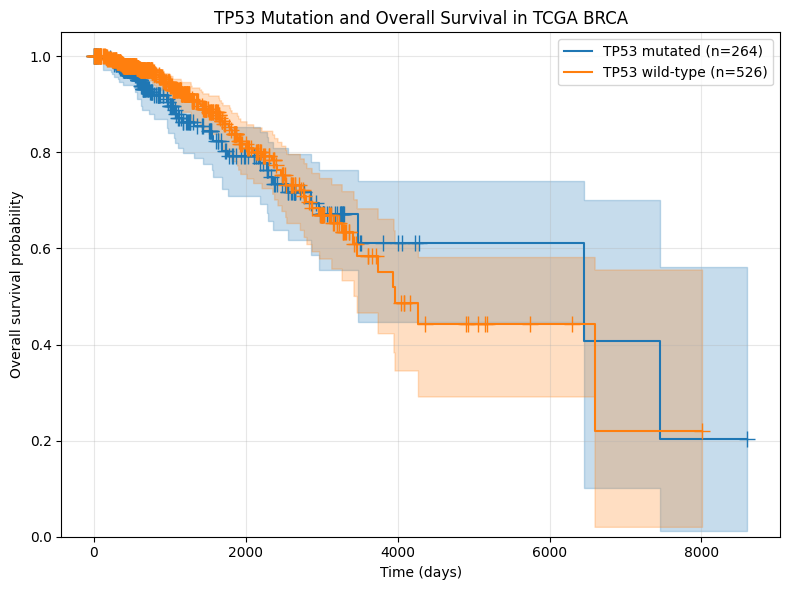

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))

for status, label in [(1, "TP53 mutated"), (0, "TP53 wild-type")]:
    group = analysis[analysis["mutation_status"] == status]

    kmf = KaplanMeierFitter()
    kmf.fit(
        durations=group["OS.time"],
        event_observed=group["OS"],
        label=f"{label} (n={len(group)})"
    )
    kmf.plot_survival_function(ax=ax, show_censors=True)

ax.set_title("TP53 Mutation and Overall Survival in TCGA BRCA")
ax.set_xlabel("Time (days)")
ax.set_ylabel("Overall survival probability")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("TP53_survival_plot.png", dpi=300)
plt.show()

I compared overall survival between 264 patients with TP53 mutations and 526 patients without identified TP53 mutations in TCGA BRCA. The mutation-positive group appears to have slightly lower survival early in follow-up, but the curves later cross. Therefore, neither group consistently shows better survival throughout the study. The confidence intervals overlap substantially and become wider later, making the late survival estimates uncertain. This plot alone does not establish a clinically meaningful difference or statistical significance. High mutation frequency does not necessarily imply an effect on overall survival. Factors such as age, cancer stage, breast cancer subtype, and treatment could influence the comparison. A driver mutation may help cancer develop without independently determining survival because outcomes also depend on other mutations, treatment response, and patient characteristics.
